# 30 - Modelo B: deteção de água e cheia (10 m)

| | |
|---|---|
| **Tarefa do plano** | S3-01 (Modelo B) e parte de S3-04 (validação por blocos espaciais e evento real) e S3-05 (pós-processamento) |
| **O que faz** | Compara features e algoritmos, escolhe o melhor com um critério definido à partida, e testa-o na cheia de janeiro de 2026 |
| **Usa** | `train_recente.parquet` (notebook 28), Sentinel-1 mensal, referência seca do radar |
| **Produz** | `models/modelo_b_radar.joblib`, mapas em `data/processed/maps/modelo_b/`, tabelas e figuras em `reports/semana_3/` |

**Ideia simples.** O radar vê através das nuvens e a água calma aparece muito
escura. O modelo aprende, com exemplos, que combinações de valores de radar
correspondem a água.

**Como o trabalho está organizado**

1. Que **features** usar? (secção 2)
2. Que **algoritmo** usar? Quatro candidatos, mesmos dados, mesmo teste. (secção 3)
3. O modelo escolhido visto de perto: erros, calibração, importância. (secções 4 e 5)
4. Mapas. (secções 6 a 8)

**De onde vêm os exemplos e como se testa sem fazer batota**

- Os rótulos JRC (2016–2021) ensinam a água "de todos os dias" (rio, lagoas, zonas
  húmidas), mas quase não têm cheias curtas. Os exemplos de cheia vêm do mapa
  oficial do Copernicus de janeiro de 2026.
- A área é dividida em blocos de 3 km. O modelo é treinado com alguns blocos da
  cheia e testado nos outros, cinco vezes, até todos terem sido testados por um
  modelo que nunca os viu. É um teste em **sítios novos do mesmo evento**: mais
  fraco do que um teste noutra cheia, mas é o que um único evento com referência
  permite.

**Termo de comparação.** Uma regra de uma linha ("VH no momento mais escuro do mês
igual ou abaixo de −22 dB = água") é avaliada ao lado. Um modelo só se justifica
se for melhor do que ela.

**Como ler as medidas** (todas entre 0 e 1; quanto mais alto, melhor)

| Medida | Pergunta a que responde |
|---|---|
| IoU | da área que o modelo **ou** a referência dizem ser água, que parte é comum aos dois? |
| F1 | equilíbrio entre não falhar água e não dar falsos alarmes |
| Kappa | concordância com a referência, descontando o que se acertaria por acaso |
| Precisão | do que o modelo chamou água, que parte era mesmo água? |
| Recall | da água que existia, que parte o modelo encontrou? |
| AUC | o modelo dá valores mais altos à água do que à não-água? (0,5 = acaso) |

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config" / "config.yaml").exists())
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ete import alerts, config, drivers, rasters
from ete import grid as G
from ete import models as M

cfg = config.load_config()
P = cfg["processing"]
REPORTS = config.path(cfg, "reports", "semana_3")       # figuras e tabelas para o relatório
pd.set_option("display.float_format", "{:,.3f}".format)

from ete import plots

## 1. Os dados de treino e de teste

In [2]:
table = M.load_table(cfg, "train_recente")
train, check, event = M.model_b_sets(cfg, table)
print(f"JRC para treino  : {len(train):,} linhas ({P['model_b_start_year']}-2021), {100 * train['label_water'].mean():.0f} % água")
print(f"JRC de controlo  : {len(check):,} linhas, nunca usadas no treino")
print(f"Cheia de 2026    : {len(event):,} linhas em {event['block_id'].nunique()} blocos de 3 km, {100 * event['label_water'].mean():.0f} % alagado")
event.groupby("fold").agg(linhas=("label_water", "size"), blocos=("block_id", "nunique"), alagado=("label_water", "mean"))

JRC para treino  : 100,000 linhas (2016-2021), 43 % água
JRC de controlo  : 60,000 linhas, nunca usadas no treino
Cheia de 2026    : 40,000 linhas em 87 blocos de 3 km, 50 % alagado


,linhas,blocos,alagado
fold,,,
0,7978,20,0.503
1,5088,14,0.373
2,8911,17,0.536
3,9893,19,0.451
4,8130,17,0.597


## 2. Que features usar? Comparação por blocos espaciais

Cada linha da tabela é um conjunto de features, com o mesmo algoritmo (Random
Forest) e o mesmo teste.

- **só JRC**: treinado sem nenhum exemplo da cheia, para mostrar o que acontece.
- **radar**: mediana e momento mais escuro do mês, diferença para a época seca, ângulo.
- **radar + terreno**: acrescenta HAND, declive e TWI.
- **radar + ótico**: acrescenta os índices do Sentinel-2 (vazios quando há nuvens).

In [3]:
rows = []
only_jrc = M.forest().fit(M._x(train, M.RADAR), train["label_water"])
p = only_jrc.predict_proba(M._x(event, M.RADAR))[:, 1]
rows.append({"features": "só JRC (radar)", **M.scores(event["label_water"], p >= P["water_probability"], event["weight"], p)})
for name, features in [("radar", M.RADAR), ("radar + terreno", M.RADAR + M.TERRAIN_B), ("radar + ótico", M.RADAR + M.OPTICAL)]:
    oof_f, check_p = M.spatial_cv_event(cfg, table, features)
    rows.append({"features": name, **M.scores(event["label_water"], oof_f >= P["water_probability"], event["weight"], oof_f),
                 "auc_agua_jrc": M.scores(check["label_water"], check_p >= 0.5, check["weight"], check_p)["auc"]})
rule = event["vh_p10"] <= M.VH_RULE_DB
rows.append({"features": f"regra simples (VH p10 <= {M.VH_RULE_DB:g} dB)", **M.scores(event["label_water"], rule, event["weight"])})
feature_sets = pd.DataFrame(rows).set_index("features").drop(columns="n")
feature_sets.round(3).to_csv(REPORTS / "30_modelo_b_features.csv")
feature_sets

,iou,f1,kappa,precisao,recall,auc,auc_agua_jrc
features,,,,,,,
só JRC (radar),0.639,0.780,0.584,0.989,0.643,0.968,NaN
radar,0.899,0.947,0.876,0.985,0.912,0.982,0.988
radar + terreno,0.906,0.951,0.884,0.989,0.915,0.987,0.992
radar + ótico,0.926,0.962,0.908,0.982,0.942,0.988,0.993
regra simples (VH p10 <= -22 dB),0.880,0.936,0.842,0.937,0.935,NaN,NaN


**Como ler esta tabela**

- A linha **só JRC** tem AUC alto mas recall mais baixo: o modelo ordena bem os
  píxeis, mas, como nunca viu uma cheia curta, deixa escapar cerca de um terço
  da área alagada.
- A **regra simples** já é boa. É o valor a bater.
- `auc_agua_jrc` mede o outro trabalho do modelo: reconhecer a água de todos os
  dias nos rótulos JRC de controlo.

**Decisão:** usar as features de **radar**. Funcionam todos os meses, com ou sem
nuvens. O ótico melhora um pouco quando existe, mas falta precisamente nos meses
de cheia; o terreno quase não acrescenta nada.

## 3. Que algoritmo usar? Quatro candidatos, o mesmo teste

| Algoritmo | O que é | Porque entra na comparação |
|---|---|---|
| Regressão logística | uma fronteira reta entre as classes | o modelo mais simples: se chegasse, não era preciso mais |
| Random Forest | muitas árvores de decisão independentes, que votam | previsto no plano; robusto e fácil de explicar |
| Gradient Boosting (HistGB) | árvores em sequência, cada uma corrige a anterior | costuma ser o mais exato em tabelas |
| XGBoost | outra implementação de gradient boosting | previsto no plano; muito usado em deteção remota |

**Critério de escolha, definido antes de ver os resultados:** o algoritmo com o
IoU médio mais alto nos cinco grupos de blocos. Se a diferença para o segundo
for menor do que a variação entre grupos de blocos, considera-se empate e
prefere-se o que ganhar em mais grupos; se continuar empatado, o mais rápido.

Todos usam configurações razoáveis e **não afinadas**: com cinco grupos de blocos
de um só evento, afinar parâmetros seria ajustar o modelo ao teste.

In [4]:
import time

oof, per_fold, rows = {}, [], []
for name, make in M.algorithms().items():
    start = time.time()
    oof[name], check_p = M.spatial_cv_event(cfg, table, M.RADAR, make)
    seconds = time.time() - start
    rows.append({"algoritmo": name, **M.scores(event["label_water"], oof[name] >= P["water_probability"], event["weight"], oof[name]),
                 "auc_agua_jrc": M.scores(check["label_water"], check_p >= 0.5, check["weight"], check_p)["auc"], "segundos": round(seconds)})
    for fold, g in event.groupby("fold"):
        per_fold.append({"modelo": name, "fold": fold, **M.scores(g["label_water"], oof[name][g.index] >= P["water_probability"], g["weight"], oof[name][g.index])})
for fold, g in event.groupby("fold"):
    per_fold.append({"modelo": "regra simples", "fold": fold, **M.scores(g["label_water"], g["vh_p10"] <= M.VH_RULE_DB, g["weight"])})
per_fold = pd.DataFrame(per_fold)
algorithms = pd.DataFrame(rows).set_index("algoritmo").drop(columns="n")
algorithms["iou_desvio_entre_blocos"] = per_fold.groupby("modelo")["iou"].std()
algorithms.round(3).to_csv(REPORTS / "30_modelo_b_algoritmos.csv")
per_fold.round(4).to_csv(REPORTS / "30_modelo_b_por_bloco.csv", index=False)
algorithms

,iou,f1,kappa,precisao,recall,auc,auc_agua_jrc,segundos,iou_desvio_entre_blocos
algoritmo,,,,,,,,,
Regressão logística,0.791,0.883,0.744,0.970,0.810,0.953,0.970,3,0.031
Random Forest,0.899,0.947,0.876,0.985,0.912,0.982,0.988,28,0.015
Gradient Boosting (HistGB),0.907,0.951,0.885,0.985,0.919,0.983,0.990,20,0.013
XGBoost,0.908,0.952,0.886,0.985,0.920,0.983,0.990,6,0.015


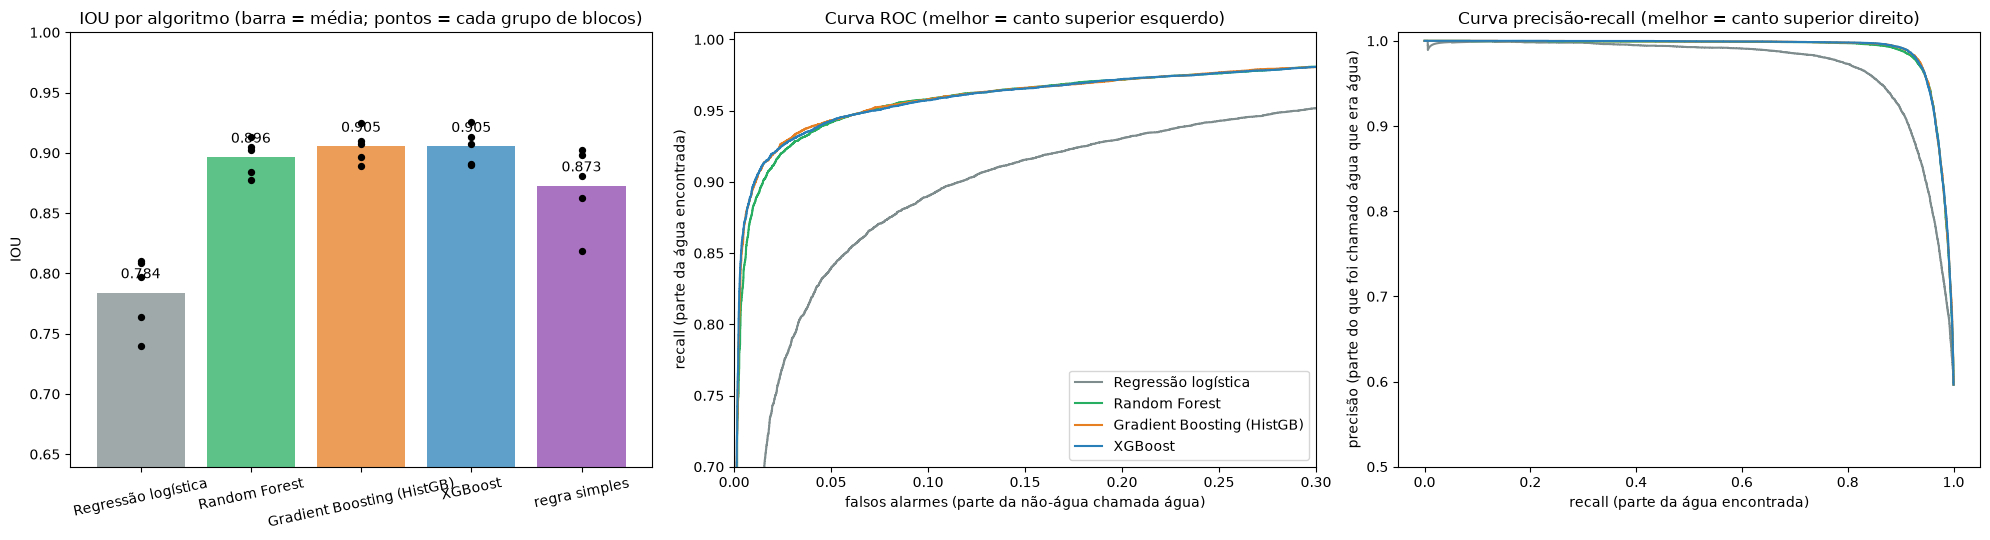

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
plots.fold_scores(axes[0], per_fold, "iou")
plots.roc_and_pr(axes[1], axes[2], event["label_water"], oof, event["weight"])
axes[1].set_xlim(0, 0.3); axes[1].set_ylim(0.7, 1.005)          # zoom: é aqui que os modelos se distinguem
plt.tight_layout(); plt.savefig(REPORTS / "30_modelo_b_algoritmos.png", dpi=110)

**Como ler os gráficos**

- **Esquerda:** cada barra é a média do IoU; cada ponto preto é um grupo de
  blocos. Pontos muito espalhados = resultado instável.
- **Centro (ROC, com zoom):** quanto mais a linha sobe junto ao eixo esquerdo,
  mais água o modelo encontra com poucos falsos alarmes.
- **Direita (precisão-recall):** quanto mais a linha se mantém em cima à medida
  que vai para a direita, melhor.

A célula seguinte aplica o critério de escolha.

In [6]:
wide = per_fold.pivot(index="fold", columns="modelo", values="iou")
ranking = algorithms["iou"].sort_values(ascending=False)
best, second = ranking.index[0], ranking.index[1]
gap, spread = ranking.iloc[0] - ranking.iloc[1], algorithms.loc[best, "iou_desvio_entre_blocos"]
if gap < spread:                                   # empate: quem ganha em mais grupos, depois o mais rápido
    tied = [n for n in ranking.index if ranking.iloc[0] - ranking[n] < spread]
    wins = {n: int(sum((wide[n] >= wide[tied].max(axis=1) - 1e-9))) for n in tied}
    best = sorted(tied, key=lambda n: (-wins[n], algorithms.loc[n, "segundos"]))[0]
    print(f"empate dentro da variação entre blocos ({spread:.3f}) entre: {', '.join(tied)}")
    print("grupos de blocos ganhos por cada um:", wins)
BEST = best
(REPORTS / "30_modelo_b_escolhido.txt").write_text(BEST)
print(f"\nALGORITMO ESCOLHIDO: {BEST}  (IoU {algorithms.loc[BEST, 'iou']:.3f}, F1 {algorithms.loc[BEST, 'f1']:.3f}, Kappa {algorithms.loc[BEST, 'kappa']:.3f})")
print(f"ganho sobre a regra simples: {algorithms.loc[BEST, 'iou'] - feature_sets.iloc[-1]['iou']:+.3f} de IoU; "
      f"melhor do que a regra em {int((wide[BEST] > wide['regra simples']).sum())} de {len(wide)} grupos de blocos")
print(f"ganho sobre a regressão logística: {algorithms.loc[BEST, 'iou'] - algorithms.loc['Regressão logística', 'iou']:+.3f} de IoU")
(wide.sub(wide["regra simples"], axis=0).drop(columns="regra simples")).round(3).rename_axis("diferença de IoU para a regra simples, por grupo de blocos", axis=1)

empate dentro da variação entre blocos (0.015) entre: XGBoost, Gradient Boosting (HistGB), Random Forest
grupos de blocos ganhos por cada um: {'XGBoost': 3, 'Gradient Boosting (HistGB)': 2, 'Random Forest': 0}

ALGORITMO ESCOLHIDO: XGBoost  (IoU 0.908, F1 0.952, Kappa 0.886)
ganho sobre a regra simples: +0.028 de IoU; melhor do que a regra em 5 de 5 grupos de blocos
ganho sobre a regressão logística: +0.117 de IoU


"diferença de IoU para a regra simples, por grupo de blocos",Gradient Boosting (HistGB),Random Forest,Regressão logística,XGBoost
fold,,,,
0,0.026,0.022,-0.099,0.028
1,0.078,0.059,-0.079,0.071
2,0.005,0.003,-0.105,0.005
3,0.044,0.032,-0.072,0.045
4,0.011,0.004,-0.088,0.015


**O que a comparação mostra**

- A **regressão logística** fica claramente atrás: a relação entre o radar e a
  água não é uma linha reta, por isso um modelo de árvores justifica-se.
- Os três modelos de árvores ficam **muito próximos uns dos outros**. A diferença
  entre eles é da ordem da variação entre grupos de blocos: com um só evento,
  não se pode afirmar que um é realmente melhor do que os outros.
- A escolha segue o critério definido à partida. Seria igualmente defensável
  qualquer dos três.

## 4. O modelo escolhido visto de perto

{'n': 40000,
 'iou': 0.9077627079074785,
 'f1': 0.95165159078212,
 'kappa': 0.8859542919355388,
 'precisao': 0.9853292391356882,
 'recall': 0.9202,
 'auc': 0.9828188400000001}

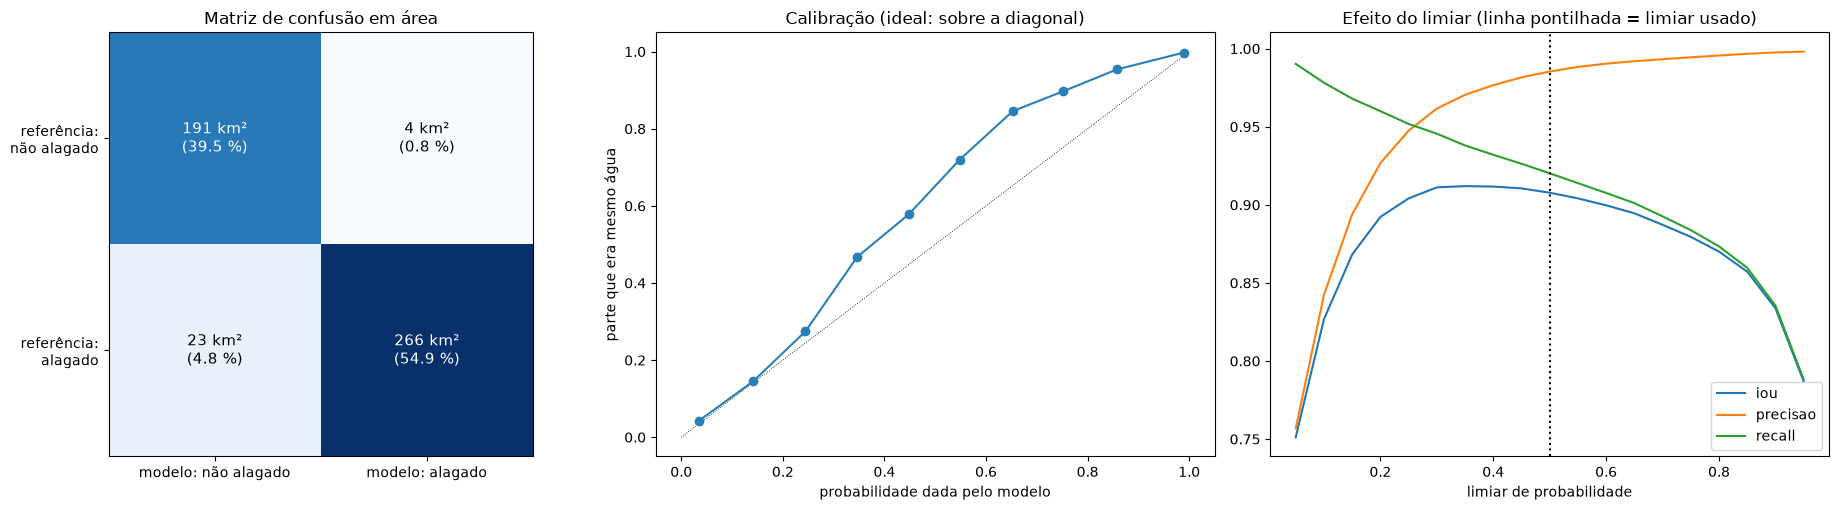

In [7]:
p_best = oof[BEST]
fig, axes = plt.subplots(1, 3, figsize=(19, 5.2))
# cada linha representa `weight` píxeis de 30 m: área em km² = peso x 900 m² / 1e6
plots.confusion(axes[0], event["label_water"], p_best >= P["water_probability"], event["weight"], 900 / 1e6)
plots.calibration(axes[1], event["label_water"], p_best, event["weight"])
thresholds = np.linspace(0.05, 0.95, 19)
curve = pd.DataFrame([M.scores(event["label_water"], p_best >= t, event["weight"]) for t in thresholds], index=thresholds)
curve[["iou", "precisao", "recall"]].plot(ax=axes[2]); axes[2].axvline(P["water_probability"], color="black", linestyle=":")
axes[2].set_xlabel("limiar de probabilidade"); axes[2].set_title("Efeito do limiar (linha pontilhada = limiar usado)")
plt.tight_layout(); plt.savefig(REPORTS / "30_modelo_b_escolhido.png", dpi=110)
M.scores(event["label_water"], p_best >= P["water_probability"], event["weight"], p_best)

**Como ler**

- **Matriz de confusão:** a diagonal são os acertos. O canto inferior esquerdo é
  a cheia que o modelo não viu; o superior direito são os falsos alarmes.
- **Calibração:** se os pontos estão sobre a diagonal, uma probabilidade de 0,8
  quer mesmo dizer "água em 80 % dos casos".
- **Efeito do limiar:** mostra que o resultado não depende de um limiar escolhido
  ao milímetro. Se o IoU se mantém alto numa faixa larga, o modelo é robusto.

## 5. Modelo final e o que ele usa

O modelo final é treinado com todas as linhas e guardado. A importância é medida
por permutação: baralha-se uma feature e vê-se quanto o AUC desce. Serve para
qualquer algoritmo.

guardado em models/modelo_b_radar.joblib (XGBoost)


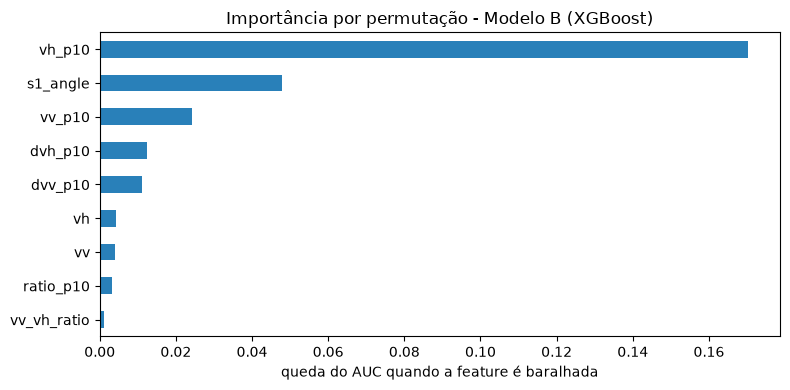

In [8]:
model = M.fit_model_b(cfg, table, M.RADAR, "modelo_b_radar", make=M.algorithms()[BEST])
sample = pd.concat([check.sample(15000, random_state=0), event.sample(15000, random_state=0)])
imp = M.importance(model, M.RADAR, M._x(sample, M.RADAR), sample["label_water"])
ax = imp.sort_values().plot.barh(figsize=(8, 4), title=f"Importância por permutação - Modelo B ({BEST})", color="#2980b9")
ax.set_xlabel("queda do AUC quando a feature é baralhada")
plt.tight_layout(); plt.savefig(REPORTS / "30_modelo_b_importancia.png", dpi=110)
print(f"guardado em models/modelo_b_radar.joblib ({BEST})")

As features do **momento mais escuro do mês** (`vh_p10`, `vv_p10`) dominam: foi por
isso que essas bandas foram acrescentadas ao Sentinel-1.

## 6. Mapa da cheia de janeiro de 2026 e comparação com o Copernicus

O modelo final é aplicado a todos os píxeis de 10 m. Manchas com menos de 25
píxeis (0,25 ha) são removidas como ruído. "Cheia" é a água fora da água
permanente.

água prevista: 329 km² | cheia (fora da água permanente): 294 km²
na área com referência: acertos 268 km², cheia não detetada 20 km², falso alarme 4.6 km²


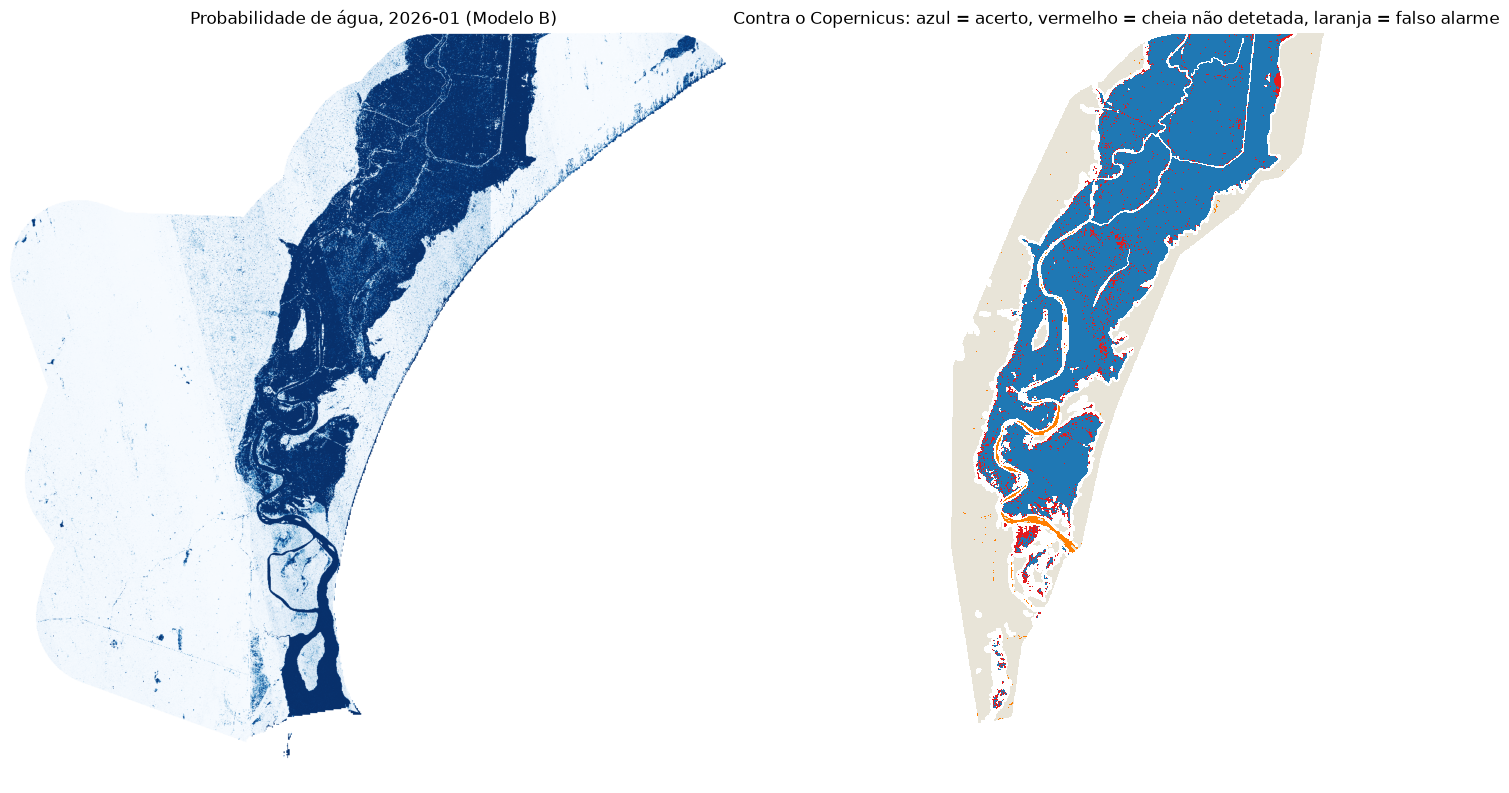

In [9]:
EVENT = "2026-01"
map_file = M.water_map(cfg, model, M.RADAR, EVENT, overwrite=True)
layers = rasters.read_bands(map_file)
reference = M.reference_raster(cfg, EVENT)

km2 = lambda mask: mask.sum() * 100 / 1e6
labelled = (reference > 0) & np.isfinite(layers["agua"])
truth, predicted = reference == 2, layers["agua"] == 1
print(f"água prevista: {km2(predicted):.0f} km² | cheia (fora da água permanente): {km2(layers['cheia'] == 1):.0f} km²")
print(f"na área com referência: acertos {km2(labelled & truth & predicted):.0f} km², cheia não detetada {km2(labelled & truth & ~predicted):.0f} km², falso alarme {km2(labelled & ~truth & predicted):.1f} km²")

agreement = np.full(reference.shape, np.nan)
agreement[labelled & ~truth & ~predicted] = 0     # seco nos dois
agreement[labelled & truth & predicted] = 1       # água nos dois
agreement[labelled & truth & ~predicted] = 2      # cheia não detetada
agreement[labelled & ~truth & predicted] = 3      # falso alarme
from matplotlib.colors import ListedColormap
fig, axes = plt.subplots(1, 2, figsize=(15, 8))
axes[0].imshow(np.where(np.isfinite(layers["probabilidade"]), layers["probabilidade"], np.nan)[::4, ::4], cmap="Blues", vmin=0, vmax=1)
axes[0].set_title(f"Probabilidade de água, {EVENT} (Modelo B)"); axes[0].axis("off")
axes[1].imshow(agreement[::4, ::4], cmap=ListedColormap(["#e8e4d8", "#1f78b4", "#e31a1c", "#ff7f00"]), vmin=0, vmax=3, interpolation="nearest")
axes[1].set_title("Contra o Copernicus: azul = acerto, vermelho = cheia não detetada, laranja = falso alarme"); axes[1].axis("off")
plt.tight_layout(); plt.savefig(REPORTS / "30_modelo_b_mapa_2026-01.png", dpi=110)

Este mapa é feito com o modelo final, que já viu a cheia toda no treino. Serve
para **ver onde** estão os erros; os números honestos de desempenho são os das
secções 3 e 4, feitos por blocos.

## 7. Polígonos da cheia para o QGIS e para a plataforma

In [10]:
polygons = M.vectorise(cfg, map_file, "cheia", config.path(cfg, "maps", "modelo_b", f"cheia_{cfg['project']['aoi_name']}_{EVENT}.gpkg"))
import geopandas as gpd
zones = gpd.read_file(polygons)
print(f"{len(zones)} zonas de cheia com mais de 0,5 ha, {zones['area_ha'].sum() / 100:.0f} km² no total -> {polygons.relative_to(ROOT)}")

407 zonas de cheia com mais de 0,5 ha, 293 km² no total -> data/processed/maps/modelo_b/cheia_marracuene_2026-01.gpkg


## 8. Outros meses

O mesmo modelo aplicado a meses sem mapa oficial. Não há referência para
confirmar estes números: servem para ver se o comportamento é plausível
(mais cheia nos meses de chuva e caudal extremos, quase nenhuma num mês seco).

,água_km2,cheia_km2,rain_basin_mm,q_max
mês,,,,
2021-02,165.300,130.700,289.200,548.900
2023-02,213.000,178.600,425.700,"2,370.700"
2023-03,222.200,187.600,61.700,403.000
2026-02,239.200,204.600,42.600,966.900
2022-08,59.100,24.700,6.400,2.200


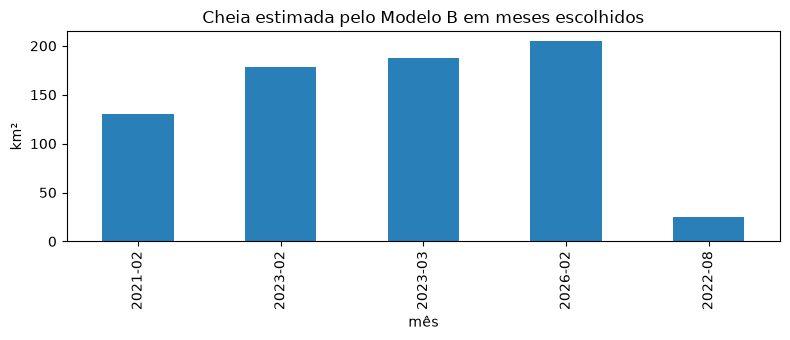

In [11]:
rows = []
for month in ["2021-02", "2023-02", "2023-03", "2026-02", "2022-08"]:
    d = rasters.read_bands(M.water_map(cfg, model, M.RADAR, month, overwrite=True), ["agua", "cheia"])
    rows.append({"mês": month, "água_km2": np.nansum(d["agua"]) / 1e4, "cheia_km2": np.nansum(d["cheia"]) / 1e4})
outros = pd.DataFrame(rows).set_index("mês").join(drivers.load_monthly_drivers(cfg)[["rain_basin_mm", "q_max"]])
ax = outros["cheia_km2"].plot.bar(figsize=(8, 3.5), color="#2980b9", ylabel="km²", title="Cheia estimada pelo Modelo B em meses escolhidos")
plt.tight_layout(); plt.savefig(REPORTS / "30_modelo_b_outros_meses.png", dpi=110)
outros.round(1)

**Atenção ao valor do mês seco.** Mesmo em agosto de 2022, sem chuva, o modelo dá
algumas dezenas de km² de "cheia". Não é cheia: são zonas húmidas e solos que o
radar vê escuros e que o JRC não conta como água permanente. É o nível de fundo
do método. Uma cheia lê-se pela diferença em relação a esse fundo, e não pelo
valor absoluto.

## As métricas são boas? Leitura de especialista

- **IoU perto de 0,9 e F1 perto de 0,95 são valores altos** para mapas de cheia
  com Sentinel-1. Em comparações publicadas com dados de referência
  independentes, é comum ver IoU entre 0,6 e 0,85.
- **Mas este número é otimista por duas razões**, que devem ser ditas sempre que
  for citado: (1) o teste é em sítios novos do mesmo evento, não noutra cheia;
  (2) metade dos mapas de referência do Copernicus também foi feita com
  Sentinel-1, ou seja, com o mesmo tipo de sensor.
- **O ganho do modelo sobre a regra simples é pequeno.** O que realmente fez a
  diferença foi a decisão de usar o momento mais escuro do mês, e não o
  algoritmo. Isto é um resultado honesto e útil: a plataforma pode até arrancar
  com a regra simples e usar o modelo como refinamento.
- **A precisão é muito alta e o recall um pouco menor**: quando o modelo diz
  "água", quase sempre é; o que falha é alguma água nas margens da cheia.
  Para um sistema de alertas, é o lado mais seguro para errar em área, mas
  significa que a extensão real pode ser um pouco maior do que a mapeada.

## Limites do Modelo B

- **Um só evento com referência.** O desempenho foi medido em sítios novos da
  cheia de janeiro de 2026. Não se sabe como se comporta em cheias mais pequenas
  ou com outro padrão.
- **A referência também é radar.** Dois dos quatro mapas do Copernicus foram
  feitos com Sentinel-1. Concordar com eles não prova que haja água debaixo de
  vegetação densa ou entre casas, onde nenhum radar a vê bem.
- **Resolução temporal mensal.** O modelo diz que houve água em algum momento do
  mês, não em que dia.
- **O mar fica de fora** do domínio; solo nu muito seco pode ser confundido com
  água (visto em 2015–2016, notebook 20).